# Experiments: how directional noise biases interferometric travel times

This notebook uses the same `simulation.py` as the app. The setup is basin scale: a station pair $r = 3$ km apart, with uncorrelated noise sources on a ring of radius 12 km and a homogeneous medium with $c = 2.2$ km/s unless noted otherwise. The noise band is centred on 2 Hz, so the wavelength is 1.1 km. The noise intensity is

$$B(\theta)=\frac{\epsilon}{2\pi} + (1-\epsilon)\,\frac{e^{\kappa\cos(\theta-\theta_0)}}{2\pi I_0(\kappa)},$$

where $\theta_0$ is the direction the noise comes **from**, measured from the A→B axis, $\kappa$ is the concentration, and $\epsilon$ is the isotropic background fraction.

Bias is always measured relative to the correlation from an isotropic noise field in the same medium. The headline number is the **apparent velocity error** $\delta c/c = -\delta t/t$ of the symmetric component $[C(t)+C(-t)]/2$, which is the quantity ambient-noise tomography usually measures (Bensen et al. 2007).

In [1]:
import numpy as np, matplotlib.pyplot as plt
import simulation as S
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
exp = S.PairExperiment(S.Model(), r=3.0)         # 2 FD runs, ~15 s
c0, t_ab = exp.model.c0, exp.r / exp.model.c0
iso = {fc: exp.correlate(exp.weights(), fc) for fc in np.round(np.arange(0.8, 2.81, 0.2), 1)}
def bias(theta0, kappa, eps=0.0, fc=2.0, pair_az=0.0):
    return exp.measure(exp.correlate(exp.weights(theta0, kappa, eps, pair_az), fc), iso[fc], fc)

## 1. What the correlation looks like
The noise comes from three directions with $\kappa = 4$: from behind B (0°), from broadside (90°), and from behind A (180°).

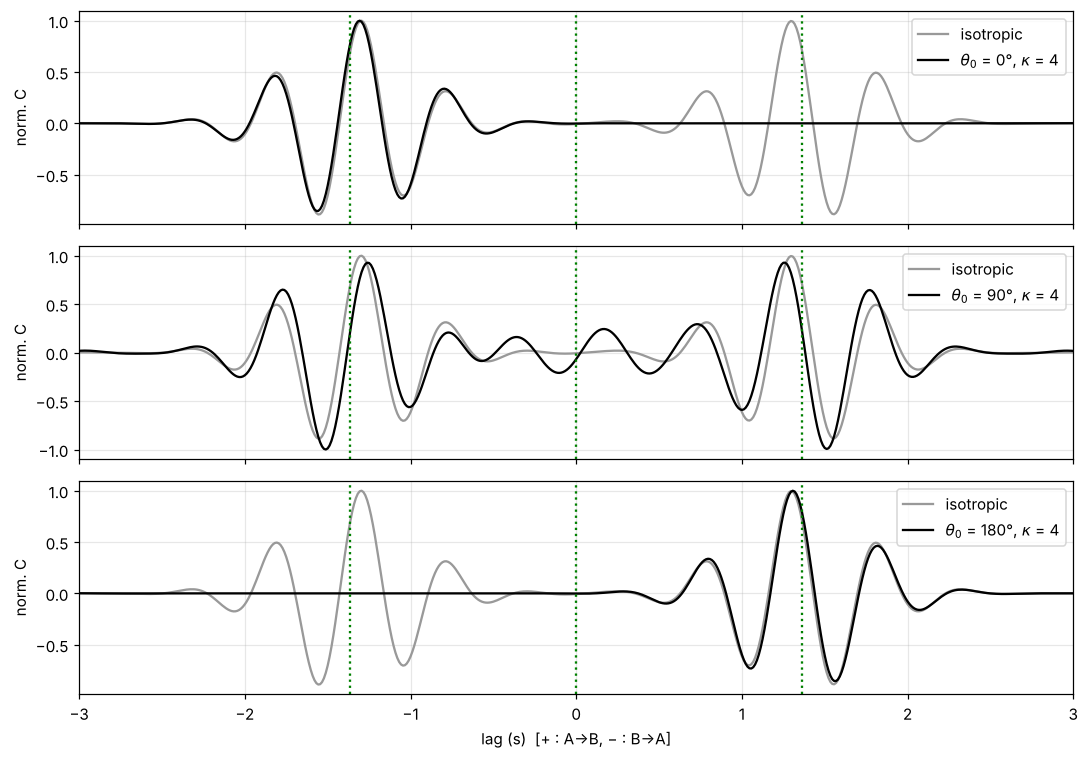

In [2]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for a, th in zip(ax, [0, 90, 180]):
    C = exp.correlate(exp.weights(np.radians(th), 4.0), 2.0)
    a.plot(exp.lags, iso[2.0] / np.abs(iso[2.0]).max(), color="0.6", label="isotropic")
    a.plot(exp.lags, C / np.abs(C).max(), "k", label=rf"$\theta_0$ = {th}°, $\kappa$ = 4")
    [a.axvline(s * t_ab, color="g", ls=":") for s in (-1, 0, 1)]
    a.set(ylabel="norm. C"); a.legend(loc="upper right")
ax[-1].set(xlabel="lag (s)  [+ : A→B, − : B→A]", xlim=(-3, 3))
plt.tight_layout()

* **Noise from an endfire direction (0° or 180°):** only one branch survives, and its travel time is nearly correct. This is the *amplitude asymmetry* that Stehly et al. (2006) used to locate noise sources.
* **Broadside noise (90°):** both branches are weak and arrive early. A spurious arrival also appears near zero lag, because broadside energy no longer cancels.

## 2. Bias vs concentration κ and dominant direction θ₀

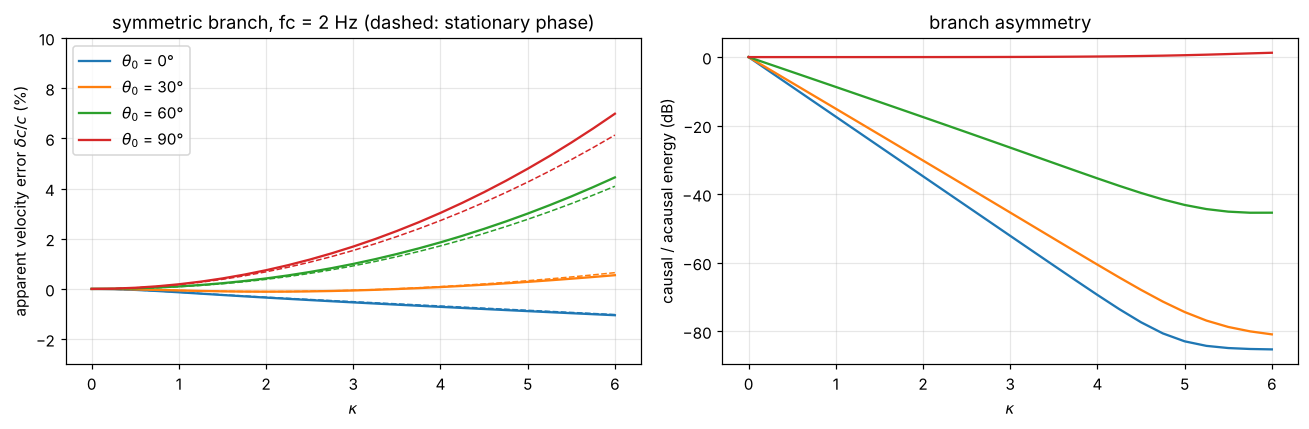

In [3]:
kappas = np.linspace(0, 6, 25)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for th in [0, 30, 60, 90]:
    res = [bias(np.radians(th), k) for k in kappas]
    pred = [exp.weaver_prediction(np.radians(th), k, 0, 2.0)["dv_sym"] for k in kappas]
    l, = ax[0].plot(kappas, [r["dv_sym"] for r in res], label=rf"$\theta_0$ = {th}°")
    ax[0].plot(kappas, pred, "--", color=l.get_color(), lw=1)
    ax[1].plot(kappas, [r["asym_db"] for r in res], color=l.get_color())
ax[0].set(xlabel=r"$\kappa$", ylabel=r"apparent velocity error $\delta c/c$ (%)",
          title="symmetric branch, fc = 2 Hz (dashed: stationary phase)", ylim=(-3, 10))
ax[1].set(xlabel=r"$\kappa$", ylabel="causal / acausal energy (dB)", title="branch asymmetry")
ax[0].legend(); plt.tight_layout()

Broadside-dominated noise makes the medium look **fast**, and by several percent once $\kappa \gtrsim 3$. With noise along the axis, the symmetric measurement is barely biased, because it is dominated by the strong endfire branch, whose stationary-phase zone has $B''/B=-\kappa$. That gives a *slow* bias, which is small and decreasing in magnitude. The stationary-phase formula tracks the FD result until the weak branch carries almost no energy.

## 3. Bias vs inter-station distance in wavelengths
The bias depends on $\omega t = 2\pi r/\lambda$. Sweeping the centre frequency $f_c$ at fixed $r$ therefore sweeps $r/\lambda$ at no extra cost. The theory predicts $|\delta c/c| \propto (r/\lambda)^{-2}$. The common rule of thumb in practice is to use only pairs with $r > 3\lambda$.

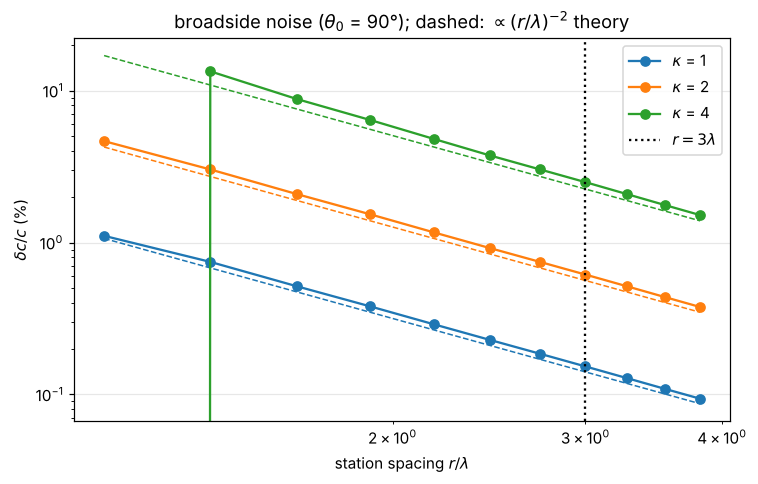

In [4]:
fcs = np.array(sorted(iso))
fig, ax = plt.subplots(figsize=(7, 4.5))
for k in [1, 2, 4]:
    dv = [bias(np.pi / 2, k, fc=fc)["dv_sym"] for fc in fcs]
    pred = [exp.weaver_prediction(np.pi / 2, k, 0, fc)["dv_sym"] for fc in fcs]
    l, = ax.loglog(exp.r * fcs / c0, dv, "o-", label=rf"$\kappa$ = {k}")
    ax.loglog(exp.r * fcs / c0, pred, "--", color=l.get_color(), lw=1)
ax.axvline(3, color="k", ls=":", label=r"$r = 3\lambda$")
ax.set(xlabel=r"station spacing $r/\lambda$", ylabel=r"$\delta c/c$ (%)",
       title=r"broadside noise ($\theta_0$ = 90°); dashed: $\propto (r/\lambda)^{-2}$ theory")
ax.legend(); plt.tight_layout()

## 4. Fake azimuthal anisotropy
A real array has pairs pointing in every direction, while the noise keeps one dominant direction, here 0° (east). Each pair is biased differently, so the apparent velocity varies with pair azimuth. An isotropic Earth therefore looks **anisotropic**. We fit $\delta c/c = a_0 + A_2\cos 2(\phi-\psi)$ by least squares (as in the regression notebook).

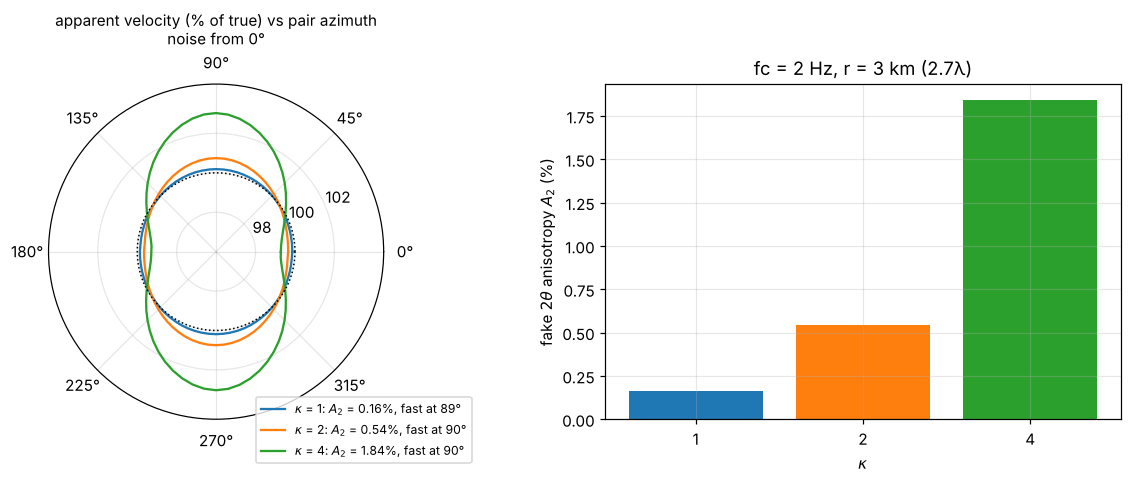

In [5]:
fig = plt.figure(figsize=(11, 4.5))
axp = fig.add_subplot(1, 2, 1, projection="polar"); axb = fig.add_subplot(1, 2, 2)
for k in [1, 2, 4]:
    az, dv, fit = exp.azimuth_sweep(0.0, k, 0.0, 2.0)
    az2, dv2 = np.r_[az, az + np.pi, az[:1]], np.r_[dv, dv, dv[:1]]    # symmetric branch: 180° periodic
    axp.plot(az2, 100 + dv2, label=rf"$\kappa$ = {k}: $A_2$ = {fit['A2']:.2f}%, fast at {np.degrees(fit['fast_az']):.0f}°")
    axb.bar(str(k), fit["A2"])
axp.plot(np.linspace(0, 2 * np.pi, 100), np.full(100, 100), "k:", lw=1)
axp.set_rlim(96, 104.5); axp.set_rticks([98, 100, 102])
axp.set_title("apparent velocity (% of true) vs pair azimuth\nnoise from 0°", fontsize=10)
axp.legend(loc="lower left", bbox_to_anchor=(0.6, -0.15), fontsize=8)
axb.set(xlabel=r"$\kappa$", ylabel=r"fake $2\theta$ anisotropy $A_2$ (%)", title="fc = 2 Hz, r = 3 km (2.7λ)")
plt.tight_layout()

Pairs perpendicular to the dominant noise direction appear fast. The resulting $2\theta$ pattern has a fast axis **perpendicular** to the noise direction, and its amplitude ($\sim$1% at $\kappa = 2$) is comparable to real crustal anisotropy. If seasonal storms rotate $\theta_0$, the fast axis rotates with them, which would show up as an apparent *seasonal* change in velocity or anisotropy.

## 5. An isotropic background (ε) reduces the bias

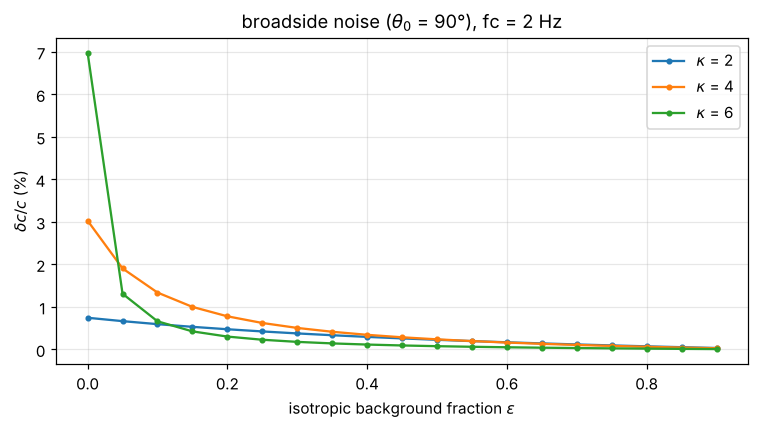

In [6]:
eps = np.linspace(0, 0.9, 19)
fig, ax = plt.subplots(figsize=(7, 4))
for k in [2, 4, 6]:
    ax.plot(eps, [bias(np.pi / 2, k, e)["dv_sym"] for e in eps], "o-", ms=3, label=rf"$\kappa$ = {k}")
ax.set(xlabel=r"isotropic background fraction $\epsilon$", ylabel=r"$\delta c/c$ (%)",
       title=r"broadside noise ($\theta_0$ = 90°), fc = 2 Hz"); ax.legend(); plt.tight_layout()

## 6. Exploratory: weak scattering
Here we add small-scale random velocity heterogeneity (100 m correlation length, 2% and 5% standard deviation). Each medium needs two new FD runs, and the reference is the isotropic correlation computed *in the same medium*. This lies **outside the verified regime**: there is no analytic reference, and the stationary-phase theory assumes ballistic waves.

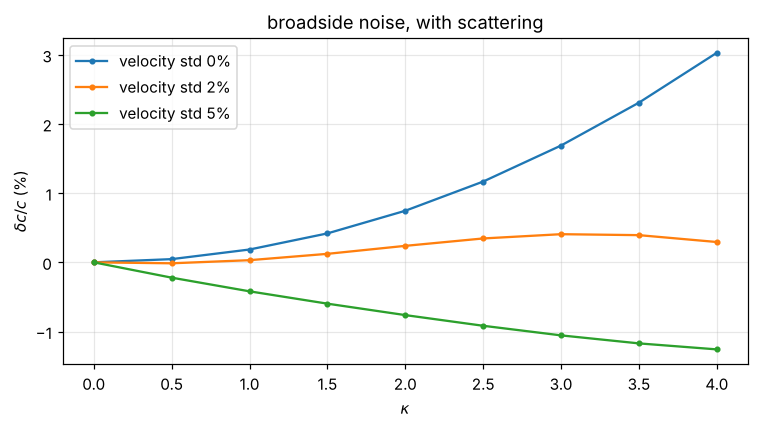

In [7]:
kap = np.linspace(0, 4, 9)
fig, ax = plt.subplots(figsize=(7, 4))
for s in [0.0, 0.02, 0.05]:
    m = S.Model() if s == 0 else S.Model(c=S.random_medium(S.Model(), rel_std=s, corr_len=0.1, seed=1))
    e = S.PairExperiment(m, r=3.0)
    ref = e.correlate(e.weights(), 2.0)
    ax.plot(kap, [e.measure(e.correlate(e.weights(np.pi / 2, k), 2.0), ref)["dv_sym"] for k in kap],
            "o-", ms=3, label=f"velocity std {100 * s:.0f}%")
ax.set(xlabel=r"$\kappa$", ylabel=r"$\delta c/c$ (%)", title="broadside noise, with scattering"); ax.legend()
plt.tight_layout()

Scattering does **not** simply remove the bias. In this realisation, 2% heterogeneity roughly cancels the ballistic (fast) bias, while 5% flips it to *slow*. Broadside noise scatters into the endfire stationary-phase zones, but it gets there along longer paths and so arrives late. This agrees qualitatively with the expectation that scattered energy only helps when the correlation reaches the multiply scattered coda (equipartition). The outcome changes from one random realisation to the next, so treat this section as exploratory. A convincing result would average several seeds (`random_medium(..., seed=k)`) and measure in a coda window.

## Summary
* The bias is controlled by the noise intensity *at and around the endfire directions* (its curvature $B''/B$), not by the overall asymmetry. Strongly one-sided noise from along the axis gives an accurate (one-branch) travel time, while broadside noise gives an apparent velocity that is too fast.
* It scales as $(r/\lambda)^{-2}$. Pairs closer than about 3λ, or long-period measurements, are most affected.
* Across an array, a single dominant noise direction produces a $2\theta$ fake anisotropy with a fast axis perpendicular to the noise direction.
* An isotropic background reduces the bias by filling the endfire stationary-phase zones. Weak scattering also fills them, but with late energy, so it can reduce the bias or flip it from fast to slow depending on its strength (exploratory).